In [1]:
!pip install mne

# **Load Data**

In [2]:
import mne
import pandas as pd

c:\Users\Victus\anaconda3\Lib\site-packages\pandas\core\computation\expressions.py:22: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.8.4' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED
c:\Users\Victus\anaconda3\Lib\site-packages\pandas\core\arrays\masked.py:56: UserWarning: Pandas requires version '1.4.2' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (


In [3]:
df = pd.read_excel('C:\\Users\\Victus\\Pictures\\Tugas Akhir\\data Responden\\data EEg\\Rekap Data\\Rekap Data ST-1.xlsx')

In [4]:
# pisah per responden
for r in df['Responden'].unique():
    df_r = df[df['Responden'] == r]

In [5]:
import numpy as np
import matplotlib.pyplot as plt

In [6]:
import numpy as np
import mne

channels = ['RAW_AF7','RAW_AF8']

raw_dict = {}

for r in df['Responden'].unique():
    print(f"Processing: {r}")

    df_r = df[df['Responden'] == r]

    data = np.array(df_r[channels]).astype(float)

    # 🔥 normalisasi (WAJIB)
    data = data - np.mean(data, axis=0)
    data = data / 1000

    data = data.T

    info = mne.create_info(
        ch_names=['AF7','AF8'],
        sfreq=256,
        ch_types='eeg'
    )

    raw = mne.io.RawArray(data, info)

    raw_dict[r] = raw

Processing: SAR
Creating RawArray with float64 data, n_channels=2, n_times=159
    Range : 0 ... 158 =      0.000 ...     0.617 secs
Ready.
Processing: FA
Creating RawArray with float64 data, n_channels=2, n_times=158
    Range : 0 ... 157 =      0.000 ...     0.613 secs
Ready.
Processing: GM
Creating RawArray with float64 data, n_channels=2, n_times=126
    Range : 0 ... 125 =      0.000 ...     0.488 secs
Ready.
Processing: DPP
Creating RawArray with float64 data, n_channels=2, n_times=120
    Range : 0 ... 119 =      0.000 ...     0.465 secs
Ready.
Processing: RA
Creating RawArray with float64 data, n_channels=2, n_times=157
    Range : 0 ... 156 =      0.000 ...     0.609 secs
Ready.
Processing: RNN
Creating RawArray with float64 data, n_channels=2, n_times=162
    Range : 0 ... 161 =      0.000 ...     0.629 secs
Ready.
Processing: S
Creating RawArray with float64 data, n_channels=2, n_times=162
    Range : 0 ... 161 =      0.000 ...     0.629 secs
Ready.
Processing: ANN
Creating 

In [7]:
data = np.array(df_r[channels]).astype(float) / 1e6
data = data.T

In [8]:
print(df_r[channels].describe())

          RAW_AF7     RAW_AF8
count  130.000000  130.000000
mean   804.208796  801.639334
std     31.304463   55.316999
min    703.919430  545.567750
25%    786.016500  785.311360
50%    800.622700  808.076950
75%    817.042150  830.036603
max    909.413940  920.696000


## **Preprocessing (Filtering)**

In [9]:
raw_filtered = {}

for r, raw in raw_dict.items():
    raw_f = raw.copy()

    raw_f.filter(1, 20, method='iir')
    raw_f.set_eeg_reference('average')

    raw_filtered[r] = raw_f

Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 20 Hz

IIR filter parameters
---------------------
Butterworth bandpass zero-phase (two-pass forward and reverse) non-causal filter:
- Filter order 16 (effective, after forward-backward)
- Cutoffs at 1.00, 20.00 Hz: -6.02, -6.02 dB

EEG channel type selected for re-referencing
Applying average reference.
Applying a custom ('EEG',) reference.
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 20 Hz

IIR filter parameters
---------------------
Butterworth bandpass zero-phase (two-pass forward and reverse) non-causal filter:
- Filter order 16 (effective, after forward-backward)
- Cutoffs at 1.00, 20.00 Hz: -6.02, -6.02 dB

EEG channel type selected for re-referencing
Applying average reference.
Applying a custom ('EEG',) reference.
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 20 Hz

IIR filter parameters
---------------------
Butterworth bandpass 

In [10]:
print(raw_filtered.keys())

dict_keys(['SAR', 'FA', 'GM', 'DPP', 'RA', 'RNN', 'S', 'ANN', 'SIT'])


## **Epoch**

In [11]:
epochs_dict = {}

for r, raw in raw_filtered.items():
    events = mne.make_fixed_length_events(raw, duration=0.3)

    if len(events) == 0:
        continue

    epochs = mne.Epochs(
        raw,
        events,
        tmin=0,
        tmax=0.3,
        baseline=None,
        preload=True
    )

    epochs_dict[r] = epochs

Not setting metadata
2 matching events found
No baseline correction applied
0 projection items activated
Using data from preloaded Raw for 2 events and 78 original time points ...
0 bad epochs dropped
Not setting metadata
2 matching events found
No baseline correction applied
0 projection items activated
Using data from preloaded Raw for 2 events and 78 original time points ...
0 bad epochs dropped
Not setting metadata
1 matching events found
No baseline correction applied
0 projection items activated
Using data from preloaded Raw for 1 events and 78 original time points ...
0 bad epochs dropped
Not setting metadata
1 matching events found
No baseline correction applied
0 projection items activated
Using data from preloaded Raw for 1 events and 78 original time points ...
0 bad epochs dropped
Not setting metadata
2 matching events found
No baseline correction applied
0 projection items activated
Using data from preloaded Raw for 2 events and 78 original time points ...
0 bad epochs dro

In [12]:
features = []

for r, epochs in epochs_dict.items():

    power = epochs.compute_tfr(
        method='morlet',
        freqs=np.arange(8, 30, 2),
        n_cycles=1
    )

    data = power.data
    mean_power = data.mean(axis=(0,1,3))

    freqs = power.freqs

    alpha = mean_power[(freqs >= 8) & (freqs <= 13)].mean()
    beta  = mean_power[(freqs > 13) & (freqs <= 30)].mean()

    features.append([r, alpha, beta])

No baseline correction applied


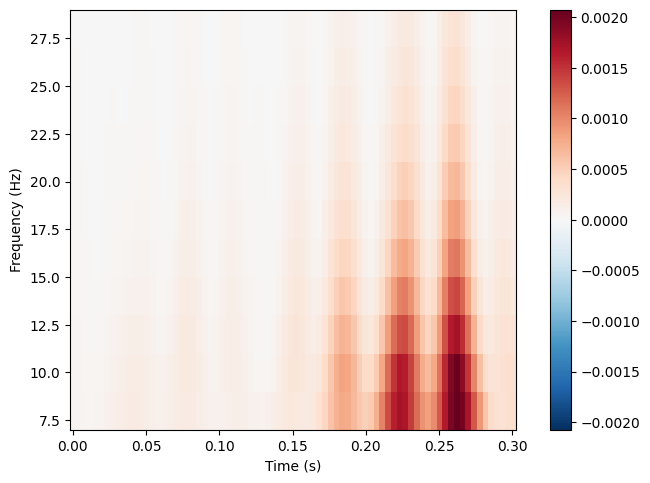

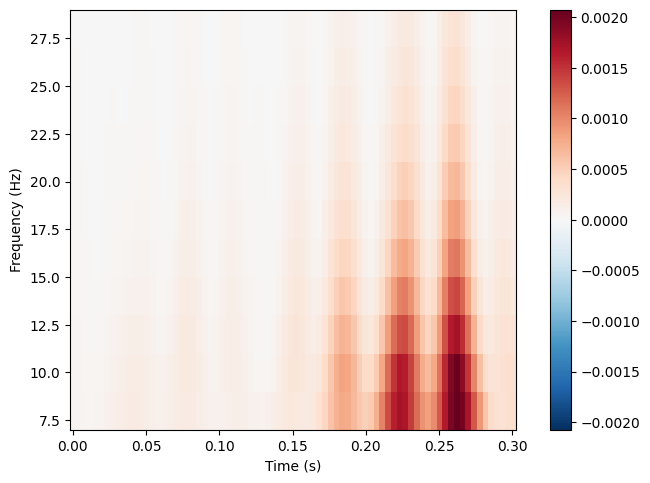

[<Figure size 640x480 with 2 Axes>, <Figure size 640x480 with 2 Axes>]

In [13]:
r = 'SAR'
epochs = epochs_dict[r]

power = epochs.compute_tfr(
    method='morlet',
    freqs=np.arange(8, 30, 2),
    n_cycles=1
)

# 🔥 WAJIB untuk data kamu
power_avg = power.average()

power_avg.plot()

Effective window size : 0.621 (s)
Plotting power spectral density (dB=True).


C:\Users\Victus\AppData\Local\Temp\ipykernel_15104\2289357254.py:1: RuntimeWarning: Channel locations not available. Disabling spatial colors.
  raw_filtered['SAR'].compute_psd().plot()
c:\Users\Victus\anaconda3\Lib\site-packages\mne\viz\utils.py:160: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  (fig or plt).show(**kwargs)


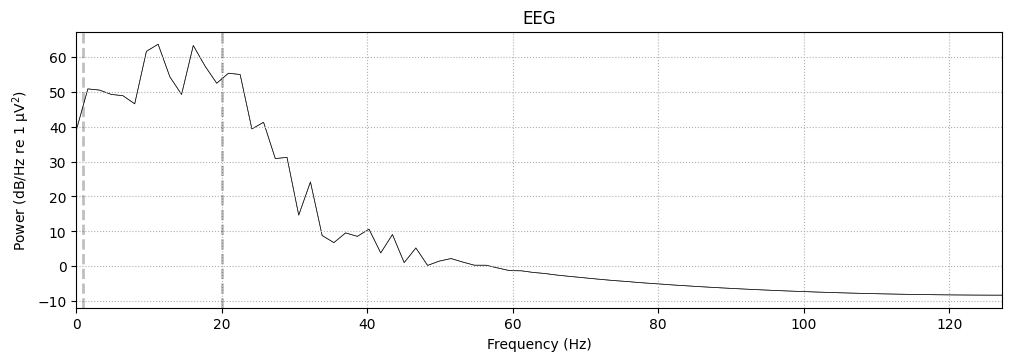

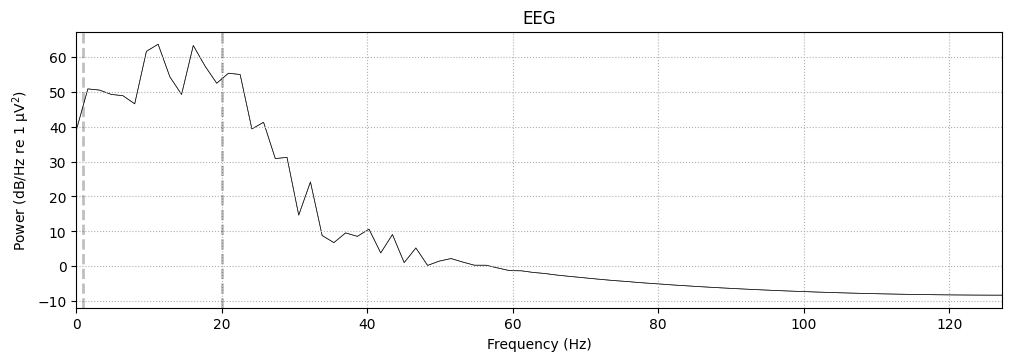

In [14]:
raw_filtered['SAR'].compute_psd().plot()

In [15]:
features = []

for r, epochs in epochs_dict.items():
    print(f"Feature extraction: {r}")

    power = epochs.compute_tfr(
        method='morlet',
        freqs=np.arange(8, 30, 2),
        n_cycles=1
    )

    # ambil data
    data = power.data  # shape: (epoch, channel, freq, time)

    # rata-rata semua dimensi
    mean_power = data.mean(axis=(0,1,3))  # hasil: per frekuensi

    freqs = power.freqs

    # 🔥 ambil alpha & beta
    alpha = mean_power[(freqs >= 8) & (freqs <= 13)].mean()
    beta  = mean_power[(freqs > 13) & (freqs <= 30)].mean()

    features.append([r, alpha, beta])

Feature extraction: SAR
Feature extraction: FA
Feature extraction: GM
Feature extraction: DPP
Feature extraction: RA
Feature extraction: RNN
Feature extraction: S
Feature extraction: ANN
Feature extraction: SIT


In [16]:
df_features = pd.DataFrame(features, columns=['Responden','Alpha','Beta'])
df_features

,Responden,Alpha,Beta
0,SAR,0.000448,0.000138
1,FA,0.141155,0.041111
2,GM,0.000608,0.000176
3,DPP,0.159426,0.043896
4,RA,0.000414,0.000121
5,RNN,0.000768,0.000224
6,S,0.000768,0.000224
7,ANN,0.000987,0.000277
8,SIT,0.001975,0.000555
